## Лабораторная работа №1 | Вариант 5

Выполнил: 

In [1]:
import numpy as np

1. Создайте единичную матрицу размером 3х3

In [2]:
matrix = np.eye(3)
print(matrix)

[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


2. Создайте кастомный dtype который описывает цвет состоящий из 4х unsigned bytes(RGBA пиксель)

In [3]:
rgba = np.dtype([('R', np.uint8), ('G', np.uint8), ('B', np.uint8), ('A', np.uint8)])
color = np.array([(255, 100, 50, 255)], dtype=rgba)
print(color)

[(255, 100, 50, 255)]


3. Как игнорировать все numpy warnings(не рекомендуем к использованию)?

In [4]:
np.seterr(all='ignore')

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

4. Создайте случайный вектор размера 10 и отсортируйте его

In [5]:
vector = np.random.rand(10)
print(np.sort(vector))

[0.03194349 0.03908037 0.09124446 0.13637815 0.20987965 0.36894575
 0.54095107 0.60129048 0.75575167 0.87785211]


5. Создайте read-only массив(неизменяемый)

In [6]:
array = np.arange(5)
array.setflags(write=False)
print(array)
print(array.flags.writeable)

[0 1 2 3 4]
False


6. Рассмотрим случайную матрицу размером 10х2, представляющую декартовы координаты, преобразуем их в полярные координаты

In [7]:
points = np.random.rand(10, 2)
x = points[:, 0]
y = points[:, 1]
r = np.sqrt(x**2 + y**2)
angle = np.arctan2(y, x)
print(np.column_stack((r, angle)))

[[0.96370781 1.3233268 ]
 [1.34556362 0.82253982]
 [0.78417072 1.22088432]
 [0.97988429 0.14157954]
 [1.34039466 0.79849218]
 [0.63786119 1.01457296]
 [0.35219463 0.72677085]
 [1.16760811 0.58817811]
 [0.61331947 1.47872063]
 [0.84201146 1.49309496]]


7. Создайте структурированный массив с координатами x и y, охватывающий область [0,1]x[0,1]

In [8]:
axis = np.linspace(0, 1, 5)
x, y = np.meshgrid(axis, axis)
grid = np.zeros(25, dtype=[('x', float), ('y', float)])
grid['x'] = x.ravel()
grid['y'] = y.ravel()
print(grid)

[(0.  , 0.  ) (0.25, 0.  ) (0.5 , 0.  ) (0.75, 0.  ) (1.  , 0.  )
 (0.  , 0.25) (0.25, 0.25) (0.5 , 0.25) (0.75, 0.25) (1.  , 0.25)
 (0.  , 0.5 ) (0.25, 0.5 ) (0.5 , 0.5 ) (0.75, 0.5 ) (1.  , 0.5 )
 (0.  , 0.75) (0.25, 0.75) (0.5 , 0.75) (0.75, 0.75) (1.  , 0.75)
 (0.  , 1.  ) (0.25, 1.  ) (0.5 , 1.  ) (0.75, 1.  ) (1.  , 1.  )]


8. Учитывая два массива X и Y, постройте матрицу Коши $C$ ($C_{ij} =\frac{1}{x_i - y_j}$)

In [9]:
x = np.random.normal(size=5)
y = np.random.normal(size=5)
cauchy = 1 / (x[:, None] - y[None, :])
print(cauchy)

[[  0.80170643 -31.37578043  -1.88614049  -0.64303873  -2.58218646]
 [  0.93564682  -4.75213481  -1.41094824  -0.57680894  -1.76731925]
 [  0.41077493   0.86564195   1.52230045  -2.71715107   1.25028906]
 [  0.79991268 -34.39422225  -1.8961439   -0.6441974   -2.6009721 ]
 [  1.17162874  -2.34908093  -1.08223951  -0.51309865  -1.28025337]]


9. Как конвертировать массив float(32 bit) к массиву целых чисел (integer 32 bit) in place?

In [10]:
values = np.array([1.5, 2.7, 3.2], dtype=np.float32)
values.view(np.int32)[:] = values.astype(np.int32)
values = values.view(np.int32)
print(values)
print(values.dtype)

[1 2 3]
int32


10. Как случайно заменить p элементов в 2D массиве?

In [11]:
array = np.arange(20).reshape(4, 5)
p = 3
positions = np.random.choice(array.size, p, replace=False)
array.flat[positions] = -1
print(array)

[[ 0  1  2  3  4]
 [ 5  6  7 -1 -1]
 [10 11 12 13 14]
 [15 -1 17 18 19]]


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Классический начальный набор данных - данные пассажиров титаника.

Файл: `data.csv`

```
PassangerId - уникальный номер пассажира
Survived - выжил человек или нет
Pclass - класс обслуживания
Name - имя человека, обращение к ней/нему
Sex - пол человека
Age - возраст на момент крушения
SibSp - количество братьев и сестер / супругов на борту "Титаника"
Parch - количество родителей / детей на борту "Титаника"
Ticket - номер билета
Fare - стоимость проезда для пассажиров
Cabin - каюта
Embarked - причал отбытия. C = Cherbourg Q = Queenstown S = Southampton
```

In [12]:
import pandas as pd

In [13]:
data = pd.read_csv('data.csv')
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


1. Узнайте сколько было на борту человек

In [14]:
print('Количество пассажиров:', len(data))

Количество пассажиров: 891


2. Какой медианный и средний возраста пассажиров

In [15]:
print('Средний возраст:', round(data['Age'].mean(), 2))
print('Медианный возраст:', round(data['Age'].median(), 2))

Средний возраст: 29.7
Медианный возраст: 28.0


3. Посчитайте процент выживаемости детей(до 16 лет) и взрослых

In [16]:
known_age = data.dropna(subset=['Age']).copy()
known_age['Группа'] = np.where(known_age['Age'] < 16, 'Дети', 'Взрослые')
print((known_age.groupby('Группа')['Survived'].mean() * 100).round(2))

Группа
Взрослые    38.19
Дети        59.04
Name: Survived, dtype: float64


4. Верна ли гипотеза, что женщины и дети сажались в шлюпки первыми и выживали больше?

In [17]:
known_age = data.dropna(subset=['Age']).copy()
known_age['Группа'] = np.where(known_age['Age'] < 16, 'Дети', known_age['Sex'].map({'female': 'Женщины', 'male': 'Мужчины'}))
print((known_age.groupby('Группа')['Survived'].mean() * 100).round(2))
print('Женщины и дети выживали чаще мужчин.')

Группа
Дети       59.04
Женщины    77.52
Мужчины    17.43
Name: Survived, dtype: float64
Женщины и дети выживали чаще мужчин.


5. Зависит ли выживаемость от класса обслуживания?

In [18]:
print((data.groupby('Pclass')['Survived'].mean() * 100).round(2))

Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


6. Посчитайте средний возраст умерших женщин и мужчин

In [19]:
dead = data[data['Survived'] == 0]
print(dead.groupby('Sex')['Age'].mean().round(2))

Sex
female    25.05
male      31.62
Name: Age, dtype: float64


7. Различается ли процент выживаемости пассажиров с хотя бы одним родственником на борту и одиночек?

In [20]:
data['С родственниками'] = (data['SibSp'] + data['Parch']) > 0
print((data.groupby('С родственниками')['Survived'].mean() * 100).round(2))

С родственниками
False    30.35
True     50.56
Name: Survived, dtype: float64


8. Различается ли средняя стоимость билета у умерших и выживших пассажиров?

In [21]:
print(data.groupby('Survived')['Fare'].mean().rename(index={0: 'Погибли', 1: 'Выжили'}).round(2))

Survived
Погибли    22.12
Выжили     48.40
Name: Fare, dtype: float64


9. Выведите максимальный и минимальный возраст выживших пассажиров во 2 классе обслуживания

In [22]:
ages = data[(data['Survived'] == 1) & (data['Pclass'] == 2)]['Age'].dropna()
print('Минимальный возраст:', ages.min())
print('Максимальный возраст:', ages.max())

Минимальный возраст: 0.67
Максимальный возраст: 62.0


10. Подтвердите или опровергните гипотезу: молодым мужчинам(от 18 лет) выжить легче, чем более взрослым

In [23]:
men = data[(data['Sex'] == 'male') & (data['Age'] >= 18)].copy()
median_age = men['Age'].median()
men['Возрастная группа'] = np.where(men['Age'] < median_age, 'Моложе медианы', 'Старше медианы')
print((men.groupby('Возрастная группа')['Survived'].mean() * 100).round(2))

Возрастная группа
Моложе медианы    14.95
Старше медианы    20.40
Name: Survived, dtype: float64


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Постройте гистограмму распределения возростов пассажиров

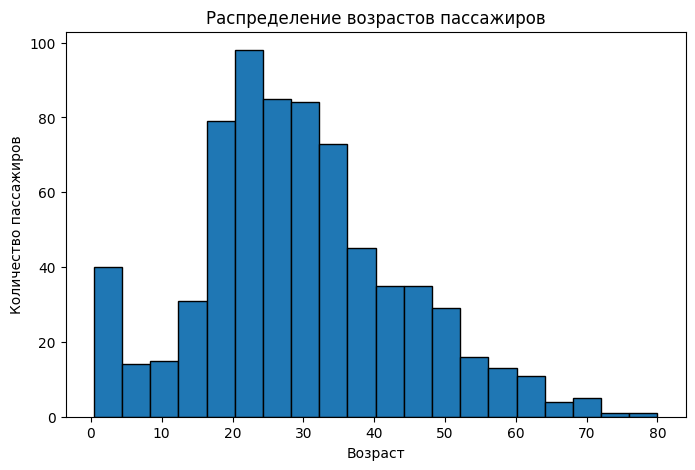

In [24]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.hist(data['Age'].dropna(), bins=20, edgecolor='black')
plt.title('Распределение возрастов пассажиров')
plt.xlabel('Возраст')
plt.ylabel('Количество пассажиров')
plt.show()

2. Постройте гистограммы распределения цен для пассажиров разных классов

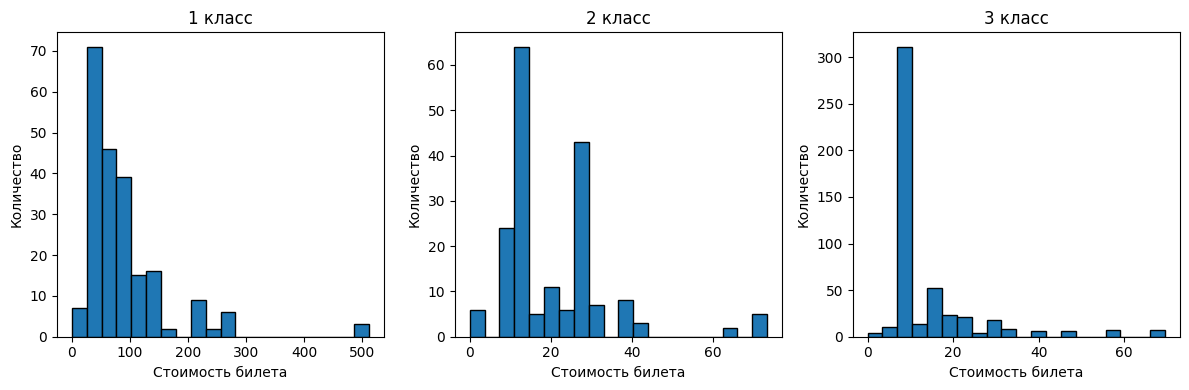

In [25]:
plt.figure(figsize=(12, 4))
for i, cls in enumerate([1, 2, 3], 1):
    plt.subplot(1, 3, i)
    plt.hist(data[data['Pclass'] == cls]['Fare'], bins=20, edgecolor='black')
    plt.title(f'{cls} класс')
    plt.xlabel('Стоимость билета')
    plt.ylabel('Количество')
plt.tight_layout()
plt.show()

3. Постройте зависимость цены от возраста пассажира

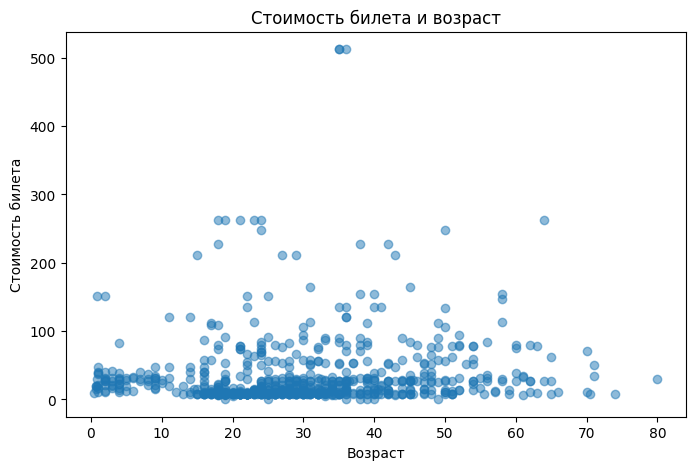

In [26]:
plt.figure(figsize=(8, 5))
plt.scatter(data['Age'], data['Fare'], alpha=0.5)
plt.title('Стоимость билета и возраст')
plt.xlabel('Возраст')
plt.ylabel('Стоимость билета')
plt.show()

4. Постройте box plot отображающий распределение цен на билеты в разных классах

<Figure size 800x500 with 0 Axes>

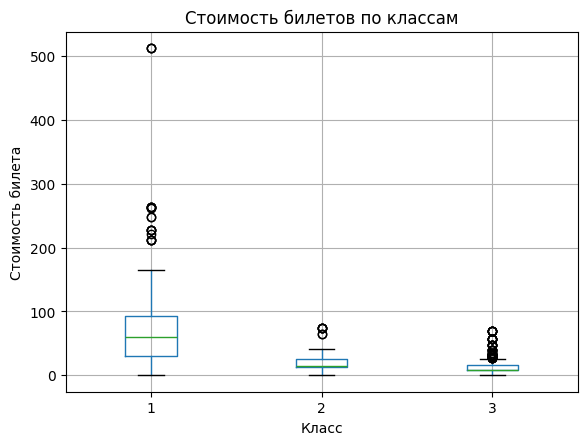

In [27]:
plt.figure(figsize=(8, 5))
data.boxplot(column='Fare', by='Pclass')
plt.title('Стоимость билетов по классам')
plt.suptitle('')
plt.xlabel('Класс')
plt.ylabel('Стоимость билета')
plt.show()

5. Визуализируйте распределение долей выживших среди мужчин, женщин и детей(до 16 лет)

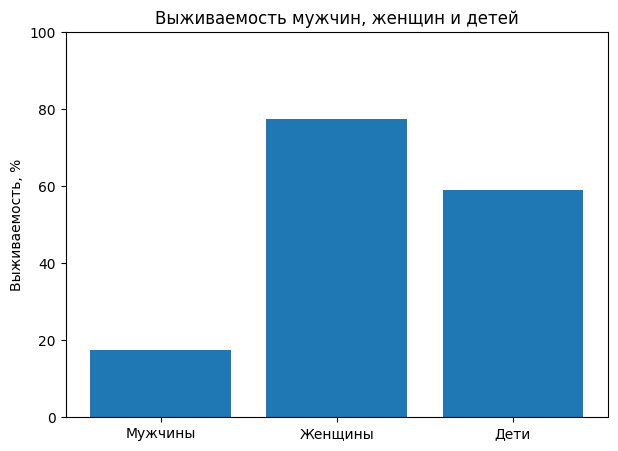

In [28]:
known_age = data.dropna(subset=['Age'])
children = known_age[known_age['Age'] < 16]
women = known_age[(known_age['Age'] >= 16) & (known_age['Sex'] == 'female')]
men = known_age[(known_age['Age'] >= 16) & (known_age['Sex'] == 'male')]
groups = ['Мужчины', 'Женщины', 'Дети']
values = [men['Survived'].mean() * 100, women['Survived'].mean() * 100, children['Survived'].mean() * 100]
plt.figure(figsize=(7, 5))
plt.bar(groups, values)
plt.ylabel('Выживаемость, %')
plt.title('Выживаемость мужчин, женщин и детей')
plt.ylim(0, 100)
plt.show()

6. Сравните плотности распределения возростов выживших и умерших пассажиров, сделайте выводы

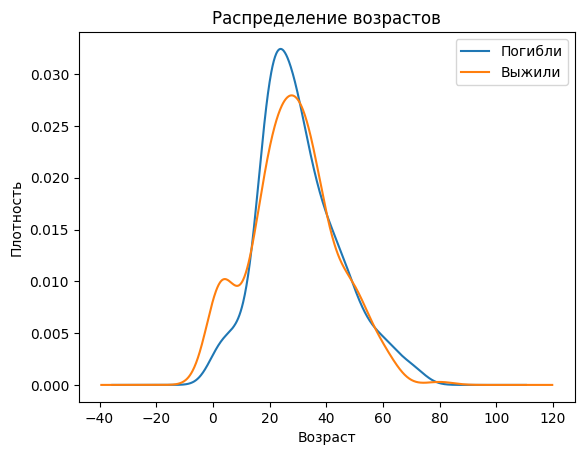

Возрастные распределения частично совпадают, но среди выживших заметна доля детей.


In [29]:
ages = data.dropna(subset=['Age'])
ages[ages['Survived'] == 0]['Age'].plot.kde(label='Погибли')
ages[ages['Survived'] == 1]['Age'].plot.kde(label='Выжили')
plt.title('Распределение возрастов')
plt.xlabel('Возраст')
plt.ylabel('Плотность')
plt.legend()
plt.show()
print('Возрастные распределения частично совпадают, но среди выживших заметна доля детей.')

7. Постройте круговую диаграмму отображающую выживаемость мужчин и женщин в разных классах обслуживания(визуализация должна быть интуитивно понятная без объяснений, женщины и мужчины соответствующих классов объеденены визуально в одну группу и 2 подгруппы)*

\* Задание на доп. балл

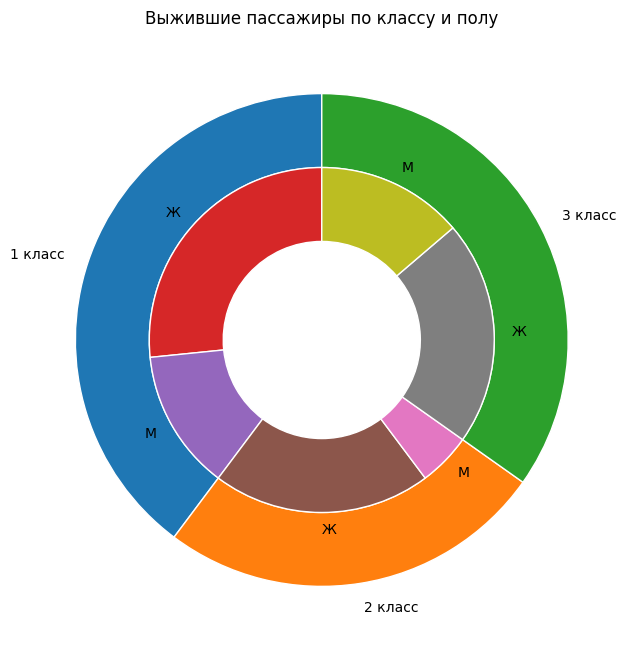

In [30]:
survivors = data[data['Survived'] == 1]
class_counts = survivors.groupby('Pclass').size()
sex_counts = survivors.groupby(['Pclass', 'Sex']).size()
outer_values = [class_counts.get(i, 0) for i in [1, 2, 3]]
inner_values = [sex_counts.get((i, s), 0) for i in [1, 2, 3] for s in ['female', 'male']]
fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(outer_values, radius=1, labels=['1 класс', '2 класс', '3 класс'], wedgeprops=dict(width=0.3, edgecolor='white'), startangle=90)
ax.pie(inner_values, radius=0.7, labels=['Ж', 'М', 'Ж', 'М', 'Ж', 'М'], wedgeprops=dict(width=0.3, edgecolor='white'), startangle=90)
ax.set_title('Выжившие пассажиры по классу и полу')
plt.show()